In [1]:
# os is used for working with folders and file paths
import os

# yaml is used to read the dataset's data.yaml file
import yaml

# shutil is used later to copy/save trained model files
import shutil

# YOLO is the object-detection model from Ultralytics
from ultralytics import YOLO

# Used later to display images and training graphs in Jupyter
from IPython.display import display, Image

print("All libraries imported successfully.")

All libraries imported successfully.


In [2]:
project_path = r"C:\Users\Lenovo\OneDrive\Documents\Robotics_projectt\Robotics_project"

# Check whether the folder actually exists.
if os.path.isdir(project_path):
    print("Project folder found successfully.")
    print()
    print("Project path:")
    print(project_path)
else:
    raise FileNotFoundError(
        "Project folder was not found.\n\n"
        "Please check that this path is correct:\n"
        + project_path
    )

Project folder found successfully.

Project path:
C:\Users\Lenovo\OneDrive\Documents\Robotics_projectt\Robotics_project


In [3]:
# ============================================================
# CELL 4 — FIND THE APPLE RIPENESS DATASET
# ============================================================

# The "archive" folder should contain the dataset you downloaded.
archive_path = os.path.join(
    project_path,
    "apple-ripeness-detection.v1i.yolov8"
)

# Check whether the archive folder exists.
if not os.path.isdir(archive_path):
    raise FileNotFoundError(
        "The archive folder was not found.\n\n"
        "Expected location:\n"
        + archive_path
    )

print("Archive folder found:")
print(archive_path)
print()

# Show everything currently inside the archive folder.
print("Folders/files inside archive:")
for item in os.listdir(archive_path):
    print(" -", item)

Archive folder found:
C:\Users\Lenovo\OneDrive\Documents\Robotics_projectt\Robotics_project\apple-ripeness-detection.v1i.yolov8

Folders/files inside archive:
 - data.yaml
 - README.dataset.txt
 - README.roboflow.txt
 - test
 - train
 - valid


In [4]:
# ============================================================
# CELL 5 — READ DATASET CONFIGURATION
# ============================================================

# The data.yaml file tells YOLO where the images are
# and what the apple-ripeness classes are.

yaml_path = os.path.join(
    archive_path,
    "data.yaml"
)

# Check that data.yaml exists.
if not os.path.isfile(yaml_path):
    raise FileNotFoundError(
        "data.yaml was not found at:\n"
        + yaml_path
    )

# Read the YAML file.
with open(
    yaml_path,
    "r",
    encoding="utf-8"
) as file:
    data_config = yaml.safe_load(file)

print("data.yaml found successfully.")
print()
print("Dataset configuration:")
print(data_config)

data.yaml found successfully.

Dataset configuration:
{'train': '../train/images', 'val': '../valid/images', 'test': '../test/images', 'nc': 3, 'names': ['overripe', 'ripe', 'unripe'], 'roboflow': {'workspace': 'dandys-workspace-jubod', 'project': 'apple-ripeness-detection-4snwq', 'version': 1, 'license': 'CC BY 4.0', 'url': 'https://universe.roboflow.com/dandys-workspace-jubod/apple-ripeness-detection-4snwq/dataset/1'}}


In [5]:
# ============================================================
# CELL 6 — VERIFY APPLE RIPENESS CLASSES
# ============================================================

# Get the class names from data.yaml.
class_names = data_config["names"]

print("Number of classes:", len(class_names))
print()

print("Apple ripeness classes:")

for class_id, class_name in enumerate(class_names):
    print(
        "Class",
        class_id,
        "→",
        class_name
    )

# Make sure we have exactly the three classes
# expected from this dataset.
expected_classes = [
    "overripe",
    "ripe",
    "unripe"
]

if class_names == expected_classes:
    print()
    print("Class verification successful.")
else:
    print()
    print("WARNING: The class names are different from expected.")
    print("Actual classes:", class_names)

Number of classes: 3

Apple ripeness classes:
Class 0 → overripe
Class 1 → ripe
Class 2 → unripe

Class verification successful.


In [6]:
# ============================================================
# CELL 7 — CHECK DATASET IMAGE COUNTS
# ============================================================

# These are the image formats that YOLO can work with.
image_extensions = (
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".webp"
)

# Check each dataset split.
for split in ["train", "valid", "test"]:
    
    # Path to the images folder for this split.
    images_path = os.path.join(
        archive_path,
        split,
        "images"
    )
    
    # Check whether the images folder exists.
    if not os.path.isdir(images_path):
        print(split, "→ images folder NOT FOUND")
        continue
    
    # Count the image files.
    image_files = [
        file
        for file in os.listdir(images_path)
        if file.lower().endswith(image_extensions)
    ]
    
    print(
        split,
        "→",
        len(image_files),
        "images"
    )

train → 1278 images
valid → 132 images
test → 46 images


In [7]:
# ============================================================
# CELL 8 — CHECK YOLO LABEL FILES
# ============================================================

# YOLO stores the bounding-box annotations in .txt files.
# Each image should normally have a corresponding label file.

for split in ["train", "valid", "test"]:
    
    # Path to the images folder
    images_path = os.path.join(
        archive_path,
        split,
        "images"
    )
    
    # Path to the labels folder
    labels_path = os.path.join(
        archive_path,
        split,
        "labels"
    )
    
    # Check that the labels folder exists
    if not os.path.isdir(labels_path):
        print(split, "→ labels folder NOT FOUND")
        continue
    
    # Count image files
    image_files = [
        file
        for file in os.listdir(images_path)
        if file.lower().endswith(image_extensions)
    ]
    
    # Count YOLO label files
    label_files = [
        file
        for file in os.listdir(labels_path)
        if file.lower().endswith(".txt")
    ]
    
    print(
        split,
        "→",
        len(image_files),
        "images |",
        len(label_files),
        "label files"
    )

train → 1278 images | 1278 label files
valid → 132 images | 132 label files
test → 46 images | 46 label files


In [8]:
# ============================================================
# CELL 9 — CHECK ONE YOLO ANNOTATION
# ============================================================

# Location of the training labels
train_labels_path = os.path.join(
    archive_path,
    "train",
    "labels"
)

# Get all label files
label_files = [
    file
    for file in os.listdir(train_labels_path)
    if file.lower().endswith(".txt")
]

# Make sure at least one label exists
if len(label_files) == 0:
    raise FileNotFoundError(
        "No YOLO label files were found in:\n"
        + train_labels_path
    )

# Select the first label file
sample_label_file = label_files[0]

# Full path to the label
sample_label_path = os.path.join(
    train_labels_path,
    sample_label_file
)

# Read the annotation
with open(
    sample_label_path,
    "r",
    encoding="utf-8"
) as file:
    annotation = file.read()

print("Sample label file:")
print(sample_label_file)
print()

print("Annotation contents:")
print(annotation)

Sample label file:
rotated_by_15_Screen-Shot-2018-06-07-at-2-57-49-PM_png.rf.4ca26e0cbe4ec9da671c5cacb6b80754.txt

Annotation contents:
0 0.53374233203125 0.175 0.438650306640625 0.125 0.340490796875 0.132142857421875 0.2484662578125 0.2 0.147239263671875 0.33928571484375 0.11963190234375 0.425 0.12269938671875 0.546428572265625 0.1625766875 0.653571427734375 0.233128833984375 0.75 0.334355828125 0.803571427734375 0.475460123046875 0.78928571484375 0.552147240234375 0.767857142578125 0.607361962890625 0.73571428515625 0.680981595703125 0.632142857421875 0.71165644140625 0.525 0.70858895703125 0.382142857421875 0.653374232421875 0.271428572265625 0.53374233203125 0.175


In [9]:
# ============================================================
# CELL 10 — VERIFY ALL SEGMENTATION LABELS
# ============================================================

# The dataset contains segmentation polygons.
# Each line should have:
#
# class_id x1 y1 x2 y2 x3 y3 ...
#
# The coordinates should be normalized between 0 and 1.

valid_labels = 0
invalid_labels = 0

invalid_examples = []

# Check train, validation and test labels
for split in ["train", "valid", "test"]:
    
    labels_path = os.path.join(
        archive_path,
        split,
        "labels"
    )
    
    # Process every label file
    for label_file in os.listdir(labels_path):
        
        if not label_file.lower().endswith(".txt"):
            continue
        
        label_path = os.path.join(
            labels_path,
            label_file
        )
        
        with open(
            label_path,
            "r",
            encoding="utf-8"
        ) as file:
            
            lines = file.readlines()
        
        for line_number, line in enumerate(lines, start=1):
            
            parts = line.strip().split()
            
            # A segmentation annotation needs:
            # 1 class ID + at least 3 (x,y) points
            if len(parts) < 7:
                invalid_labels += 1
                
                if len(invalid_examples) < 5:
                    invalid_examples.append(
                        (
                            split,
                            label_file,
                            line_number,
                            "Too few values"
                        )
                    )
                
                continue
            
            try:
                # First value is the class ID
                class_id = int(parts[0])
                
                # Remaining values are polygon coordinates
                coordinates = [
                    float(value)
                    for value in parts[1:]
                ]
                
                # There must be an even number of coordinates
                # because they occur as x,y pairs.
                if len(coordinates) % 2 != 0:
                    raise ValueError(
                        "Odd number of coordinates"
                    )
                
                # Class must be 0, 1 or 2
                if class_id not in [0, 1, 2]:
                    raise ValueError(
                        "Invalid class ID"
                    )
                
                # Every coordinate should be between 0 and 1
                if not all(
                    0.0 <= value <= 1.0
                    for value in coordinates
                ):
                    raise ValueError(
                        "Coordinate outside 0-1 range"
                    )
                
                valid_labels += 1
                
            except Exception as error:
                
                invalid_labels += 1
                
                if len(invalid_examples) < 5:
                    invalid_examples.append(
                        (
                            split,
                            label_file,
                            line_number,
                            str(error)
                        )
                    )

print("Label verification complete.")
print()
print("Valid annotations  :", valid_labels)
print("Invalid annotations:", invalid_labels)

if invalid_labels == 0:
    print()
    print("SUCCESS: All segmentation annotations are valid.")
else:
    print()
    print("WARNING: Some annotations need inspection.")
    print()
    
    for example in invalid_examples:
        print(example)

Label verification complete.

Valid annotations  : 1477
Invalid annotations: 3


('train', 'saltandpepper_Screen-Shot-2018-06-08-at-5-11-24-PM_png.rf.44d1f906ba0755b392a2e211eb3d6547.txt', 1, 'Too few values')
('train', 'saltandpepper_Screen-Shot-2018-06-08-at-5-11-24-PM_png.rf.451b38eca77bc144b842f2fa1ca43ebe.txt', 1, 'Too few values')
('train', 'saltandpepper_Screen-Shot-2018-06-08-at-5-11-24-PM_png.rf.ece9805dd68d16d5c706d234ff837db2.txt', 1, 'Too few values')


In [10]:
# ============================================================
# CELL 11 — INSPECT INVALID ANNOTATION FILES
# ============================================================

# These are the three files reported by Cell 10.
invalid_files = [
    "saltandpepper_Screen-Shot-2018-06-08-at-5-11-24-PM_png.rf.44d1f906ba0755b392a2e211eb3d6547.txt",
    "saltandpepper_Screen-Shot-2018-06-08-at-5-11-24-PM_png.rf.451b38eca77bc144b842f2fa1ca43ebe.txt",
    "saltandpepper_Screen-Shot-2018-06-08-at-5-11-24-PM_png.rf.ece9805dd68d16d5c706d234ff837db.txt"
]

# Location of the training labels
train_labels_path = os.path.join(
    archive_path,
    "train",
    "labels"
)

# Inspect each problematic file
for label_file in invalid_files:

    label_path = os.path.join(
        train_labels_path,
        label_file
    )

    print("=" * 70)
    print("FILE:")
    print(label_file)
    print()

    if not os.path.isfile(label_path):
        print("ERROR: File was not found.")
        continue

    # Read the complete file
    with open(
        label_path,
        "r",
        encoding="utf-8"
    ) as file:
        contents = file.read()

    print("RAW CONTENT:")
    print(repr(contents))
    print()

    print("NORMAL CONTENT:")
    print(contents)

FILE:
saltandpepper_Screen-Shot-2018-06-08-at-5-11-24-PM_png.rf.44d1f906ba0755b392a2e211eb3d6547.txt

RAW CONTENT:
'1 0.5888671875 0.4990234375 0.001953125 0.0009765625'

NORMAL CONTENT:
1 0.5888671875 0.4990234375 0.001953125 0.0009765625
FILE:
saltandpepper_Screen-Shot-2018-06-08-at-5-11-24-PM_png.rf.451b38eca77bc144b842f2fa1ca43ebe.txt

RAW CONTENT:
'1 0.5888671875 0.4990234375 0.001953125 0.0009765625'

NORMAL CONTENT:
1 0.5888671875 0.4990234375 0.001953125 0.0009765625
FILE:
saltandpepper_Screen-Shot-2018-06-08-at-5-11-24-PM_png.rf.ece9805dd68d16d5c706d234ff837db.txt

ERROR: File was not found.


In [11]:
# ============================================================
# CELL 12 — CREATE DETECTION DATASET FROM SEGMENTATION DATA
# ============================================================

# We will create a separate dataset for YOLO object detection.
# The original Roboflow dataset will NOT be changed.
#
# Segmentation polygon:
#     class x1 y1 x2 y2 x3 y3 ...
#
# will be converted into:
#     class center_x center_y width height

detection_dataset_path = os.path.join(
    project_path,
    "apple_ripeness_detection"
)

# Create folders for train, valid and test
for split in ["train", "valid", "test"]:
    
    os.makedirs(
        os.path.join(
            detection_dataset_path,
            split,
            "images"
        ),
        exist_ok=True
    )
    
    os.makedirs(
        os.path.join(
            detection_dataset_path,
            split,
            "labels"
        ),
        exist_ok=True
    )

print("Detection dataset folders created successfully.")
print()
print(detection_dataset_path)

Detection dataset folders created successfully.

C:\Users\Lenovo\OneDrive\Documents\Robotics_projectt\Robotics_project\apple_ripeness_detection


In [12]:
# ============================================================
# CELL 13 — CONVERT SEGMENTATION TO DETECTION FORMAT
# ============================================================

# This cell converts polygon annotations into normal YOLO
# bounding-box annotations.
#
# Original:
# class x1 y1 x2 y2 x3 y3 ...
#
# New:
# class center_x center_y width height

image_extensions = (
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".webp"
)

total_images_copied = 0
total_annotations_converted = 0
total_annotations_skipped = 0

for split in ["train", "valid", "test"]:

    # --------------------------------------------------------
    # Original dataset folders
    # --------------------------------------------------------

    source_images = os.path.join(
        archive_path,
        split,
        "images"
    )

    source_labels = os.path.join(
        archive_path,
        split,
        "labels"
    )

    # --------------------------------------------------------
    # New detection dataset folders
    # --------------------------------------------------------

    destination_images = os.path.join(
        detection_dataset_path,
        split,
        "images"
    )

    destination_labels = os.path.join(
        detection_dataset_path,
        split,
        "labels"
    )

    # If a split does not exist, skip it.
    if not os.path.isdir(source_images):
        print(split, "folder not found - skipped.")
        continue

    print()
    print("Processing:", split)

    # --------------------------------------------------------
    # Process every image
    # --------------------------------------------------------

    for image_file in os.listdir(source_images):

        if not image_file.lower().endswith(image_extensions):
            continue

        # Full image path
        source_image_path = os.path.join(
            source_images,
            image_file
        )

        # Corresponding label filename
        label_file = (
            os.path.splitext(image_file)[0]
            + ".txt"
        )

        source_label_path = os.path.join(
            source_labels,
            label_file
        )

        # If there is no label, skip this image.
        if not os.path.isfile(source_label_path):
            continue

        # ----------------------------------------------------
        # Read original annotation
        # ----------------------------------------------------

        with open(
            source_label_path,
            "r",
            encoding="utf-8"
        ) as file:

            lines = file.readlines()

        converted_annotations = []

        # ----------------------------------------------------
        # Convert every annotation
        # ----------------------------------------------------

        for line in lines:

            parts = line.strip().split()

            # Empty lines are ignored.
            if len(parts) == 0:
                continue

            try:

                # First value = class ID
                class_id = int(parts[0])

                # Remaining values = coordinates
                values = [
                    float(value)
                    for value in parts[1:]
                ]

                # ------------------------------------------------
                # CASE 1:
                # Standard YOLO bounding box
                #
                # class cx cy width height
                # ------------------------------------------------

                if len(values) == 4:

                    cx, cy, width, height = values

                    # Check coordinates
                    if not (
                        0 <= cx <= 1
                        and 0 <= cy <= 1
                        and 0 < width <= 1
                        and 0 < height <= 1
                    ):
                        total_annotations_skipped += 1
                        continue

                # ------------------------------------------------
                # CASE 2:
                # Polygon/segmentation annotation
                #
                # x1 y1 x2 y2 x3 y3 ...
                # ------------------------------------------------

                elif len(values) >= 6 and len(values) % 2 == 0:

                    x_coordinates = values[0::2]
                    y_coordinates = values[1::2]

                    # Make sure coordinates are valid.
                    if not all(
                        0 <= value <= 1
                        for value in values
                    ):
                        total_annotations_skipped += 1
                        continue

                    # Find bounding-box limits.
                    x_min = min(x_coordinates)
                    x_max = max(x_coordinates)

                    y_min = min(y_coordinates)
                    y_max = max(y_coordinates)

                    # Convert polygon to bounding box.
                    cx = (x_min + x_max) / 2
                    cy = (y_min + y_max) / 2

                    width = x_max - x_min
                    height = y_max - y_min

                    # Reject zero-size boxes.
                    if width <= 0 or height <= 0:
                        total_annotations_skipped += 1
                        continue

                # ------------------------------------------------
                # Unknown annotation format
                # ------------------------------------------------

                else:

                    total_annotations_skipped += 1
                    continue

                # ------------------------------------------------
                # Save converted YOLO annotation
                # ------------------------------------------------

                new_line = (
                    f"{class_id} "
                    f"{cx:.6f} "
                    f"{cy:.6f} "
                    f"{width:.6f} "
                    f"{height:.6f}\n"
                )

                converted_annotations.append(new_line)

                total_annotations_converted += 1

            except Exception:

                total_annotations_skipped += 1

        # ----------------------------------------------------
        # Copy image only if it has valid annotations
        # ----------------------------------------------------

        if len(converted_annotations) > 0:

            destination_image_path = os.path.join(
                destination_images,
                image_file
            )

            shutil.copy2(
                source_image_path,
                destination_image_path
            )

            destination_label_path = os.path.join(
                destination_labels,
                label_file
            )

            with open(
                destination_label_path,
                "w",
                encoding="utf-8"
            ) as file:

                file.writelines(
                    converted_annotations
                )

            total_images_copied += 1


print()
print("=" * 60)
print("CONVERSION COMPLETE")
print("=" * 60)

print("Images copied              :", total_images_copied)
print("Annotations converted     :", total_annotations_converted)
print("Annotations skipped       :", total_annotations_skipped)


Processing: train

Processing: valid

Processing: test

CONVERSION COMPLETE
Images copied              : 1429
Annotations converted     : 1480
Annotations skipped       : 0


In [13]:
# ============================================================
# CELL 14 — VERIFY CONVERTED YOLO BOUNDING BOXES
# ============================================================

# This cell checks that every converted annotation has
# the correct YOLO detection format:
#
# class_id center_x center_y width height
#
# and that all values are valid.

valid_annotations = 0
invalid_annotations = 0
invalid_examples = []

for split in ["train", "valid", "test"]:

    labels_path = os.path.join(
        detection_dataset_path,
        split,
        "labels"
    )

    if not os.path.isdir(labels_path):
        continue

    for label_file in os.listdir(labels_path):

        if not label_file.lower().endswith(".txt"):
            continue

        label_path = os.path.join(
            labels_path,
            label_file
        )

        with open(
            label_path,
            "r",
            encoding="utf-8"
        ) as file:

            lines = file.readlines()

        for line_number, line in enumerate(
            lines,
            start=1
        ):

            parts = line.strip().split()

            try:

                # A normal YOLO detection annotation
                # must contain exactly 5 values.
                if len(parts) != 5:
                    raise ValueError(
                        "Annotation does not contain 5 values"
                    )

                # Read the values.
                class_id = int(parts[0])

                cx = float(parts[1])
                cy = float(parts[2])
                width = float(parts[3])
                height = float(parts[4])

                # Check class ID.
                if class_id not in [0, 1, 2]:
                    raise ValueError(
                        "Invalid class ID"
                    )

                # Check center coordinates.
                if not (
                    0 <= cx <= 1
                    and 0 <= cy <= 1
                ):
                    raise ValueError(
                        "Center coordinate outside 0-1"
                    )

                # Width and height must be positive.
                if not (
                    0 < width <= 1
                    and 0 < height <= 1
                ):
                    raise ValueError(
                        "Invalid width or height"
                    )

                valid_annotations += 1

            except Exception as error:

                invalid_annotations += 1

                if len(invalid_examples) < 5:

                    invalid_examples.append(
                        (
                            split,
                            label_file,
                            line_number,
                            str(error)
                        )
                    )


print("=" * 60)
print("BOUNDING BOX VERIFICATION")
print("=" * 60)

print()
print("Valid annotations  :", valid_annotations)
print("Invalid annotations:", invalid_annotations)

if invalid_annotations == 0:

    print()
    print("SUCCESS!")
    print("All converted YOLO bounding boxes are valid.")

else:

    print()
    print("WARNING: Some annotations are invalid.")
    print()

    for example in invalid_examples:
        print(example)

BOUNDING BOX VERIFICATION

Valid annotations  : 1480
Invalid annotations: 0

SUCCESS!
All converted YOLO bounding boxes are valid.


In [14]:
# ============================================================
# CELL 15 — CREATE DETECTION DATA.YAML
# ============================================================

# This YAML file tells YOLO:
# 1. Where the training images are
# 2. Where the validation images are
# 3. Where the test images are
# 4. What the three apple-ripeness classes are

detection_yaml_path = os.path.join(
    detection_dataset_path,
    "data.yaml"
)

# Create the dataset configuration.
detection_data_config = {
    "path": detection_dataset_path,
    "train": "train/images",
    "val": "valid/images",
    "test": "test/images",
    "names": [
        "overripe",
        "ripe",
        "unripe"
    ]
}

# Write the configuration to data.yaml.
with open(
    detection_yaml_path,
    "w",
    encoding="utf-8"
) as file:

    yaml.safe_dump(
        detection_data_config,
        file,
        sort_keys=False
    )

print("Detection data.yaml created successfully.")
print()
print("Location:")
print(detection_yaml_path)
print()
print("Contents:")
print("-" * 60)

with open(
    detection_yaml_path,
    "r",
    encoding="utf-8"
) as file:

    print(file.read())

Detection data.yaml created successfully.

Location:
C:\Users\Lenovo\OneDrive\Documents\Robotics_projectt\Robotics_project\apple_ripeness_detection\data.yaml

Contents:
------------------------------------------------------------
path: C:\Users\Lenovo\OneDrive\Documents\Robotics_projectt\Robotics_project\apple_ripeness_detection
train: train/images
val: valid/images
test: test/images
names:
- overripe
- ripe
- unripe



In [15]:
# ============================================================
# CELL 16 — VERIFY YOLO DATASET
# ============================================================

# Path to your pretrained YOLO model.
# We will use this only to check that YOLO can read
# the new dataset correctly before training.

base_model_path = os.path.join(
    project_path,
    "yolo26n.pt"
)

# Check that the pretrained model exists.
if not os.path.isfile(base_model_path):
    raise FileNotFoundError(
        "yolo26n.pt was not found at:\n"
        + base_model_path
    )

print("Pretrained model found:")
print(base_model_path)
print()

# Load the pretrained YOLO model.
check_model = YOLO(base_model_path)

print("YOLO model loaded successfully.")
print()
print("Testing the dataset configuration...")

Pretrained model found:
C:\Users\Lenovo\OneDrive\Documents\Robotics_projectt\Robotics_project\yolo26n.pt

YOLO model loaded successfully.

Testing the dataset configuration...


In [16]:
# ============================================================
# CELL 17 — VALIDATE DATASET WITH YOLO
# ============================================================

# YOLO will now read the training, validation and test
# images and labels from our new data.yaml file.

validation_results = check_model.val(
    
    # Our newly created detection dataset
    data=detection_yaml_path,
    
    # Image size used for the validation check
    imgsz=640,
    
    # Small batch size because you are using CPU
    batch=4,
    
    # Use CPU
    device="cpu"
)

print()
print("=" * 60)
print("DATASET VALIDATION COMPLETED")
print("=" * 60)

Ultralytics 8.4.135  Python-3.13.0 torch-2.13.0+cpu CPU (Intel Core i5-1035G1 1.00GHz)
YOLO26n summary (fused): 122 layers, 2,408,932 parameters, 0 gradients, 5.5 GFLOPs
WARNING val: Slow image access detected (ping: 1.40.7 ms, read: 1.30.3 MB/s, size: 27.6 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning C:\Users\Lenovo\OneDrive\Documents\Robotics_projectt\Robotics_project\apple_ripeness_detection\valid\labels... 132 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 132/132 165.3it/s 0.8s0.1s
val: New cache created: C:\Users\Lenovo\OneDrive\Documents\Robotics_projectt\Robotics_project\apple_ripeness_detection\valid\labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 33/33 1.2it/s 28.4s0.7ss
                   all        132        139    0.00749      0.171    0.00474    0.00273
                person         31

In [17]:
# ============================================================
# CELL 18 — CHECK DETECTION DATASET CONFIGURATION
# ============================================================

# Read our newly created detection data.yaml again.
with open(
    detection_yaml_path,
    "r",
    encoding="utf-8"
) as file:
    detection_config_check = yaml.safe_load(file)

print("Detection YAML:")
print("=" * 60)

print(detection_config_check)

print()
print("Class names from YAML:")
print("=" * 60)

for class_id, class_name in enumerate(
    detection_config_check["names"]
):
    print(
        class_id,
        "→",
        class_name
    )

print()
print("Dataset path:")
print(detection_config_check["path"])

print()
print("Training path:")
print(detection_config_check["train"])

print()
print("Validation path:")
print(detection_config_check["val"])

print()
print("Test path:")
print(detection_config_check["test"])

Detection YAML:
{'path': 'C:\\Users\\Lenovo\\OneDrive\\Documents\\Robotics_projectt\\Robotics_project\\apple_ripeness_detection', 'train': 'train/images', 'val': 'valid/images', 'test': 'test/images', 'names': ['overripe', 'ripe', 'unripe']}

Class names from YAML:
0 → overripe
1 → ripe
2 → unripe

Dataset path:
C:\Users\Lenovo\OneDrive\Documents\Robotics_projectt\Robotics_project\apple_ripeness_detection

Training path:
train/images

Validation path:
valid/images

Test path:
test/images


In [18]:
# ============================================================
# CELL 19 — LOAD YOLO MODEL FOR TRAINING
# ============================================================

# Path to your pretrained YOLO26n model.
base_model_path = os.path.join(
    project_path,
    "yolo26n.pt"
)

# Make sure the model file exists.
if not os.path.isfile(base_model_path):
    raise FileNotFoundError(
        "The YOLO26n model was not found at:\n"
        + base_model_path
    )

# Load a fresh copy of the pretrained model.
model = YOLO(base_model_path)

print("YOLO model loaded successfully.")
print()
print("Model:")
print(base_model_path)
print()
print("Model task:")
print(model.task)

YOLO model loaded successfully.

Model:
C:\Users\Lenovo\OneDrive\Documents\Robotics_projectt\Robotics_project\yolo26n.pt

Model task:
detect


In [19]:
# ============================================================
# CELL 20 — CHECK TRAINING CONFIGURATION
# ============================================================

print("TRAINING CONFIGURATION")
print("=" * 60)

print()
print("Model:")
print(base_model_path)

print()
print("Dataset:")
print(detection_yaml_path)

print()
print("Classes:")
for class_id, class_name in enumerate(
    detection_config_check["names"]
):
    print(
        class_id,
        "→",
        class_name
    )

print()
print("Number of classes:")
print(len(detection_config_check["names"]))

print()
print("Training images:")
print(
    len([
        f for f in os.listdir(
            os.path.join(
                detection_dataset_path,
                "train",
                "images"
            )
        )
        if f.lower().endswith(image_extensions)
    ])
)

print()
print("Validation images:")
print(
    len([
        f for f in os.listdir(
            os.path.join(
                detection_dataset_path,
                "valid",
                "images"
            )
        )
        if f.lower().endswith(image_extensions)
    ])
)

print()
print("Test images:")
print(
    len([
        f for f in os.listdir(
            os.path.join(
                detection_dataset_path,
                "test",
                "images"
            )
        )
        if f.lower().endswith(image_extensions)
    ])
)

print()
print("=" * 60)
print("READY FOR TRAINING")
print("=" * 60)

TRAINING CONFIGURATION

Model:
C:\Users\Lenovo\OneDrive\Documents\Robotics_projectt\Robotics_project\yolo26n.pt

Dataset:
C:\Users\Lenovo\OneDrive\Documents\Robotics_projectt\Robotics_project\apple_ripeness_detection\data.yaml

Classes:
0 → overripe
1 → ripe
2 → unripe

Number of classes:
3

Training images:
1251

Validation images:
132

Test images:
46

READY FOR TRAINING


In [20]:
# ============================================================
# CELL 21 — TRAIN THE APPLE RIPENESS YOLO MODEL
# ============================================================

# Start training using the pretrained YOLO26n model.
#
# Classes:
#   0 = overripe
#   1 = ripe
#   2 = unripe

training_results = model.train(

    # --------------------------------------------------------
    # Dataset
    # --------------------------------------------------------
    data=detection_yaml_path,

    # --------------------------------------------------------
    # Number of training epochs
    # --------------------------------------------------------
    # We start with 10 epochs so that we can check whether
    # everything is working correctly.
    epochs=10,

    # --------------------------------------------------------
    # Image resolution
    # --------------------------------------------------------
    imgsz=640,

    # --------------------------------------------------------
    # Batch size
    # --------------------------------------------------------
    # A smaller batch is safer for CPU/RAM limitations.
    batch=4,

    # --------------------------------------------------------
    # Hardware
    # --------------------------------------------------------
    # Your current system is using CPU.
    device="cpu",

    # --------------------------------------------------------
    # DataLoader workers
    # --------------------------------------------------------
    # 0 is safer on Windows/Jupyter and avoids multiprocessing
    # related errors.
    workers=0,

    # --------------------------------------------------------
    # Where training results will be saved
    # --------------------------------------------------------
    project=os.path.join(
        project_path,
        "runs",
        "maturity"
    ),

    # Name of this training run
    name="apple_ripeness",

    # Save the model checkpoints
    save=True,

    # Validate after each epoch
    val=True,

    # Create plots/results after training
    plots=True
)

print()
print("=" * 60)
print("TRAINING COMPLETED")
print("=" * 60)

New https://pypi.org/project/ultralytics/8.4.164 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.135  Python-3.13.0 torch-2.13.0+cpu CPU (Intel Core i5-1035G1 1.00GHz)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\Users\Lenovo\OneDrive\Documents\Robotics_projectt\Robotics_project\apple_ripeness_detection\data.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=10, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_wi

C:\Users\Lenovo\AppData\Local\Programs\Python\Python313\Lib\site-packages\mlflow\tracking\_tracking_service\utils.py:184: FutureWarning: The filesystem tracking backend (e.g., './mlruns') is deprecated as of February 2026. Consider transitioning to a database backend (e.g., 'sqlite:///mlflow.db') to take advantage of the latest MLflow features. See https://mlflow.org/docs/latest/self-hosting/migrate-from-file-store for migration guidance.
  return FileStore(store_uri, store_uri)
2026/09/28 15:19:13 INFO mlflow.tracking.fluent: Experiment with name 'C:\Users\Lenovo\OneDrive\Documents\Robotics_projectt\Robotics_project\runs\maturity' does not exist. Creating a new experiment.


MLflow: logging run_id(42759cc971bf4e68b493c0fc236a2a1f) to runs\mlflow
MLflow: view at http://127.0.0.1:5000 with 'mlflow server --backend-store-uri runs\mlflow'
MLflow: disable with 'yolo settings mlflow=False'
Using 1251 train, 132 val images for fraction=1.0 at imgsz=640
Using 0 dataloader workers
Logging results to C:\Users\Lenovo\OneDrive\Documents\Robotics_projectt\Robotics_project\runs\maturity\apple_ripeness
Starting training for 10 epochs...
Closing dataloader mosaic

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
       1/10         0G     0.5366      8.628    0.02159          3        640: 100% ━━━━━━━━━━━━ 313/313 4.3s/it 22:403.3ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 17/17 1.7s/it 28.7s1.7ss
                   all        132        139      0.825      0.229      0.456      0.346

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
       2/10   

In [21]:
# ============================================================
# CELL 22 — LOCATE THE TRAINED MODEL
# ============================================================

# YOLO saves the trained models inside:
#
# runs/
#   maturity/
#       apple_ripeness/
#           weights/
#               best.pt
#               last.pt

training_folder = os.path.join(
    project_path,
    "runs",
    "maturity",
    "apple_ripeness"
)

weights_folder = os.path.join(
    training_folder,
    "weights"
)

best_model_path = os.path.join(
    weights_folder,
    "best.pt"
)

last_model_path = os.path.join(
    weights_folder,
    "last.pt"
)

# Check whether best.pt exists.
if os.path.isfile(best_model_path):

    print("SUCCESS: Best trained model found.")
    print()
    print("best.pt:")
    print(best_model_path)

else:

    print("ERROR: best.pt was not found.")
    print()
    print("Expected location:")
    print(best_model_path)
    
    print()
    print("Files/folders found in the training directory:")
    
    if os.path.isdir(training_folder):
        for item in os.listdir(training_folder):
            print(" -", item)

SUCCESS: Best trained model found.

best.pt:
C:\Users\Lenovo\OneDrive\Documents\Robotics_projectt\Robotics_project\runs\maturity\apple_ripeness\weights\best.pt


In [22]:
# ============================================================
# CELL 23 — LOAD AND VERIFY TRAINED MODEL
# ============================================================

# Load the best model produced during training.
trained_model = YOLO(best_model_path)

print("Trained model loaded successfully.")
print()

# Display the task of the trained model.
print("Model task:")
print(trained_model.task)

print()

# Display the classes learned by the model.
print("Model classes:")
for class_id, class_name in trained_model.names.items():
    print(
        class_id,
        "→",
        class_name
    )

Trained model loaded successfully.

Model task:
detect

Model classes:
0 → overripe
1 → ripe
2 → unripe


In [23]:
# ============================================================
# CELL 24 — VALIDATE THE TRAINED APPLE RIPENESS MODEL
# ============================================================

# Validate the trained best model on the validation dataset.
# This calculates important performance metrics such as:
#
# Precision
# Recall
# mAP@50
# mAP@50-95

validation_results = trained_model.val(
    
    # Use our converted apple-ripeness dataset
    data=detection_yaml_path,
    
    # Image size
    imgsz=640,
    
    # Small batch size for CPU
    batch=4,
    
    # Use CPU
    device="cpu",
    
    # Save validation plots
    plots=True
)

print()
print("=" * 60)
print("TRAINED MODEL VALIDATION COMPLETED")
print("=" * 60)

Ultralytics 8.4.135  Python-3.13.0 torch-2.13.0+cpu CPU (Intel Core i5-1035G1 1.00GHz)
YOLO26n summary (fused): 122 layers, 2,375,421 parameters, 0 gradients, 5.3 GFLOPs
WARNING val: Slow image access detected (ping: 1.20.8 ms, read: 34.412.7 MB/s, size: 28.5 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning C:\Users\Lenovo\OneDrive\Documents\Robotics_projectt\Robotics_project\apple_ripeness_detection\valid\labels.cache... 132 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 132/132 967.9Kit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 33/33 2.6it/s 12.6s0.4s
                   all        132        139       0.65      0.704      0.726      0.665
              overripe         31         32      0.808      0.906      0.879      0.846
                  ripe         84         88      0.809      0.625      0.812 

In [26]:
# ============================================================
# CELL 25 — CREATE FINAL RESULTS FOLDER
# ============================================================

# We will keep a permanent copy of the trained model
# and all important training graphs here.

final_results_path = os.path.join(
    project_path,
    "trained_models",
    "apple_ripeness_model"
)

# Create the folder if it doesn't already exist.
os.makedirs(
    final_results_path,
    exist_ok=True
)

print("Final results folder created:")
print(final_results_path)

Final results folder created:
C:\Users\Lenovo\OneDrive\Documents\Robotics_projectt\Robotics_project\trained_models\apple_ripeness_model


In [27]:
# ============================================================
# CELL 26 — SAVE TRAINED MODEL FILES
# ============================================================

best_model_saved_path = os.path.join(
    final_results_path,
    "apple_ripeness_best.pt"
)

last_model_saved_path = os.path.join(
    final_results_path,
    "apple_ripeness_last.pt"
)

# Save the best model
if os.path.isfile(best_model_path):
    shutil.copy2(
        best_model_path,
        best_model_saved_path
    )
    
    print("Best model saved:")
    print(best_model_saved_path)
else:
    print("best.pt not found.")

# Save the last model, if available
if os.path.isfile(last_model_path):
    shutil.copy2(
        last_model_path,
        last_model_saved_path
    )
    
    print()
    print("Last model saved:")
    print(last_model_saved_path)
else:
    print()
    print("last.pt not found.")

Best model saved:
C:\Users\Lenovo\OneDrive\Documents\Robotics_projectt\Robotics_project\trained_models\apple_ripeness_model\apple_ripeness_best.pt

Last model saved:
C:\Users\Lenovo\OneDrive\Documents\Robotics_projectt\Robotics_project\trained_models\apple_ripeness_model\apple_ripeness_last.pt


In [28]:
# ============================================================
# CELL 27 — SAVE TRAINING GRAPHS
# ============================================================

# Folder containing the original training results
training_folder = os.path.join(
    project_path,
    "runs",
    "maturity",
    "apple_ripeness"
)

# Important graphs generated during training
graph_files = [
    "results.png",
    "confusion_matrix.png",
    "confusion_matrix_normalized.png",
    "BoxP_curve.png",
    "BoxR_curve.png",
    "BoxPR_curve.png",
    "BoxF1_curve.png"
]

print("Saving training graphs...")
print()

saved_graphs = []

for graph_name in graph_files:
    source_path = os.path.join(
        training_folder,
        graph_name
    )
    
    destination_path = os.path.join(
        final_results_path,
        graph_name
    )
    
    if os.path.isfile(source_path):
        shutil.copy2(
            source_path,
            destination_path
        )
        saved_graphs.append(graph_name)
        print("Saved:", graph_name)
    else:
        print("Not found:", graph_name)

print()
print("Total graphs saved:", len(saved_graphs))
print("Saved in:")
print(final_results_path)

Saving training graphs...

Saved: results.png
Saved: confusion_matrix.png
Saved: confusion_matrix_normalized.png
Saved: BoxP_curve.png
Saved: BoxR_curve.png
Saved: BoxPR_curve.png
Saved: BoxF1_curve.png

Total graphs saved: 7
Saved in:
C:\Users\Lenovo\OneDrive\Documents\Robotics_projectt\Robotics_project\trained_models\apple_ripeness_model


In [29]:
# ============================================================
# CELL 28 — SAVE DATASET CONFIGURATION
# ============================================================

# Path to the detection dataset YAML used for training
source_yaml_path = detection_yaml_path

# Destination inside the permanent results folder
saved_yaml_path = os.path.join(
    final_results_path,
    "data.yaml"
)

# Copy the training configuration
if os.path.isfile(source_yaml_path):
    shutil.copy2(
        source_yaml_path,
        saved_yaml_path
    )
    
    print("Dataset configuration saved:")
    print(saved_yaml_path)
else:
    print("data.yaml not found:")
    print(source_yaml_path)

Dataset configuration saved:
C:\Users\Lenovo\OneDrive\Documents\Robotics_projectt\Robotics_project\trained_models\apple_ripeness_model\data.yaml


In [30]:
# ============================================================
# CELL 29 — VERIFY SAVED RESULTS
# ============================================================

print("Checking final results folder...")
print()

# List everything in the permanent folder
saved_files = sorted(
    os.listdir(final_results_path)
)

for file_name in saved_files:
    file_path = os.path.join(
        final_results_path,
        file_name
    )
    
    if os.path.isfile(file_path):
        file_size_mb = os.path.getsize(file_path) / (1024 * 1024)
        print(f"{file_name:<35} {file_size_mb:.2f} MB")

print()
print("Final results folder:")
print(final_results_path)

print()
print("Total files saved:", len(saved_files))

Checking final results folder...

BoxF1_curve.png                     0.19 MB
BoxPR_curve.png                     0.12 MB
BoxP_curve.png                      0.17 MB
BoxR_curve.png                      0.16 MB
apple_ripeness_best.pt              5.14 MB
apple_ripeness_last.pt              5.14 MB
confusion_matrix.png                0.11 MB
confusion_matrix_normalized.png     0.14 MB
data.yaml                           0.00 MB
results.png                         0.27 MB

Final results folder:
C:\Users\Lenovo\OneDrive\Documents\Robotics_projectt\Robotics_project\trained_models\apple_ripeness_model

Total files saved: 10


In [31]:
# ============================================================
# CELL 30 — FIND A TEST APPLE IMAGE
# ============================================================

test_images_path = os.path.join(
    project_path,
    "apple_ripeness_detection",
    "test",
    "images"
)

# Get image files from the test folder
test_image_files = [
    f for f in os.listdir(test_images_path)
    if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp"))
]

print("Test image folder:")
print(test_images_path)

print()
print("Number of test images:", len(test_image_files))

if len(test_image_files) > 0:
    test_image_path = os.path.join(
        test_images_path,
        test_image_files[0]
    )
    
    print()
    print("Selected test image:")
    print(test_image_path)
else:
    print()
    print("No test images found.")

Test image folder:
C:\Users\Lenovo\OneDrive\Documents\Robotics_projectt\Robotics_project\apple_ripeness_detection\test\images

Number of test images: 46

Selected test image:
C:\Users\Lenovo\OneDrive\Documents\Robotics_projectt\Robotics_project\apple_ripeness_detection\test\images\rotated_by_15_Screen-Shot-2018-06-08-at-4-59-36-PM_png.rf.e3bccb2a9aabd69fd479cfd3f74efebe.jpg


Image path:
C:\Users\Lenovo\OneDrive\Documents\Robotics_projectt\Robotics_project\apple_ripeness_detection\test\images\rotated_by_15_Screen-Shot-2018-06-08-at-4-59-36-PM_png.rf.e3bccb2a9aabd69fd479cfd3f74efebe.jpg

Image size:
(512, 512)

Displaying test image:


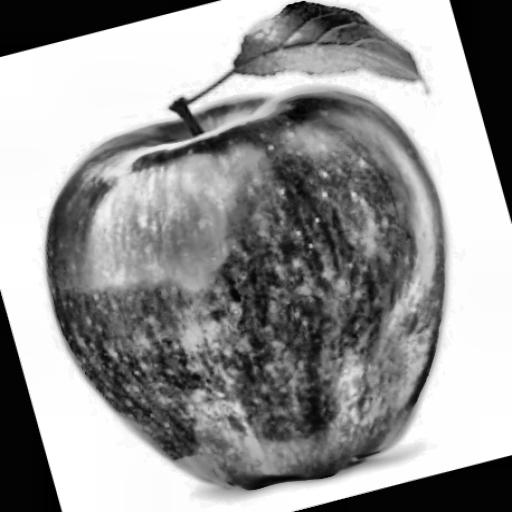

In [32]:
# ============================================================
# CELL 31 — DISPLAY SELECTED TEST IMAGE
# ============================================================

from IPython.display import display
from PIL import Image

# Open the selected test image
test_image = Image.open(test_image_path)

print("Image path:")
print(test_image_path)

print()
print("Image size:")
print(test_image.size)

print()
print("Displaying test image:")

display(test_image)

In [33]:
# ============================================================
# CELL 32 — RUN TRAINED MODEL ON TEST IMAGE
# ============================================================

# Run the trained model on the selected test image
prediction_results = trained_model.predict(
    source=test_image_path,
    imgsz=640,
    conf=0.25,
    device="cpu"
)

print("Prediction completed.")
print()
print("Image:")
print(test_image_path)

print()
print("Number of result objects:", len(prediction_results))


image 1/1 C:\Users\Lenovo\OneDrive\Documents\Robotics_projectt\Robotics_project\apple_ripeness_detection\test\images\rotated_by_15_Screen-Shot-2018-06-08-at-4-59-36-PM_png.rf.e3bccb2a9aabd69fd479cfd3f74efebe.jpg: 640x640 1 ripe, 231.0ms
Speed: 15.1ms preprocess, 231.0ms inference, 3.1ms postprocess per image at shape (1, 3, 640, 640)
Prediction completed.

Image:
C:\Users\Lenovo\OneDrive\Documents\Robotics_projectt\Robotics_project\apple_ripeness_detection\test\images\rotated_by_15_Screen-Shot-2018-06-08-at-4-59-36-PM_png.rf.e3bccb2a9aabd69fd479cfd3f74efebe.jpg

Number of result objects: 1


In [34]:
# ============================================================
# CELL 33 — EXTRACT PREDICTION DETAILS
# ============================================================

# Get the first prediction result
result = prediction_results[0]

# Check whether any objects were detected
if result.boxes is not None and len(result.boxes) > 0:

    print("Detected objects:", len(result.boxes))
    print()

    for i, box in enumerate(result.boxes):

        # Class ID
        class_id = int(box.cls[0].item())

        # Class name
        class_name = trained_model.names[class_id]

        # Confidence
        confidence = float(box.conf[0].item())

        # Bounding box coordinates
        x1, y1, x2, y2 = box.xyxy[0].tolist()

        print(f"Object {i + 1}")
        print("----------------------------")
        print("Class ID:", class_id)
        print("Ripeness:", class_name)
        print(f"Confidence: {confidence:.4f}")
        print(
            f"Bounding box: "
            f"x1={x1:.2f}, y1={y1:.2f}, "
            f"x2={x2:.2f}, y2={y2:.2f}"
        )
        print()

else:
    print("No objects detected.")

Detected objects: 1

Object 1
----------------------------
Class ID: 1
Ripeness: ripe
Confidence: 0.8725
Bounding box: x1=35.70, y1=5.99, x2=453.25, y2=483.01



In [35]:
# ============================================================
# CELL 34 — CALCULATE APPLE CENTER PIXEL COORDINATES
# ============================================================

if result.boxes is not None and len(result.boxes) > 0:

    print("Apple center coordinates:")
    print()

    for i, box in enumerate(result.boxes):

        # Bounding box coordinates
        x1, y1, x2, y2 = box.xyxy[0].tolist()

        # Calculate center pixel coordinates
        u = (x1 + x2) / 2
        v = (y1 + y2) / 2

        # Get image dimensions
        image_width, image_height = test_image.size

        print(f"Object {i + 1}")
        print("----------------------------")
        print(f"Image width  : {image_width} pixels")
        print(f"Image height : {image_height} pixels")
        print(f"Center u     : {u:.2f} pixels")
        print(f"Center v     : {v:.2f} pixels")
        print()

else:
    print("No detected apple available.")

Apple center coordinates:

Object 1
----------------------------
Image width  : 512 pixels
Image height : 512 pixels
Center u     : 244.47 pixels
Center v     : 244.50 pixels



In [36]:
# ============================================================
# CELL 10 — CHECK TRAINING IMAGE COLOR CHANNELS
# ============================================================

import numpy as np

# Path to the training images
train_images_path = r"C:\Users\Lenovo\OneDrive\Documents\Robotics_projectt\Robotics_project\apple_ripeness_detection\train\images"

# Find the first image
train_image_files = [
    f for f in os.listdir(train_images_path)
    if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp"))
]

if len(train_image_files) == 0:
    print("No training images found.")

else:
    sample_train_image_path = os.path.join(
        train_images_path,
        train_image_files[0]
    )

    # Open image
    sample_train_image = Image.open(
        sample_train_image_path
    )

    # Convert to NumPy array
    image_array = np.array(sample_train_image)

    print("Sample training image:")
    print(sample_train_image_path)

    print()
    print("PIL image mode:", sample_train_image.mode)
    print("Image shape:", image_array.shape)

    print()

    # Check whether the image is truly grayscale
    if len(image_array.shape) == 2:
        print("RESULT: TRUE GRAYSCALE IMAGE")
        print("The image has only one intensity channel.")

    elif image_array.shape[2] >= 3:

        red_channel = image_array[:, :, 0]
        green_channel = image_array[:, :, 1]
        blue_channel = image_array[:, :, 2]

        same_rg = np.array_equal(red_channel, green_channel)
        same_gb = np.array_equal(green_channel, blue_channel)

        if same_rg and same_gb:
            print("RESULT: 3-CHANNEL IMAGE BUT VISUALLY GRAYSCALE")
            print("R, G and B channels contain identical values.")
        else:
            print("RESULT: COLOR IMAGE")
            print("R, G and B channels contain different values.")

    else:
        print("RESULT: UNUSUAL IMAGE FORMAT")

Sample training image:
C:\Users\Lenovo\OneDrive\Documents\Robotics_projectt\Robotics_project\apple_ripeness_detection\train\images\rotated_by_15_Screen-Shot-2018-06-07-at-2-57-49-PM_png.rf.4ca26e0cbe4ec9da671c5cacb6b80754.jpg

PIL image mode: RGB
Image shape: (512, 512, 3)

RESULT: 3-CHANNEL IMAGE BUT VISUALLY GRAYSCALE
R, G and B channels contain identical values.


In [37]:
# ============================================================
# CELL 13 — TEST ON MULTIPLE DATASET TEST IMAGES
# ============================================================

test_images_path = r"C:\Users\Lenovo\OneDrive\Documents\Robotics_projectt\Robotics_project\apple_ripeness_detection\test\images"

test_files = [
    f for f in os.listdir(test_images_path)
    if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp"))
]

# Use the first 10 test images
test_files = sorted(test_files)[:10]

print("Testing", len(test_files), "dataset images...")
print()

for file_name in test_files:

    image_path = os.path.join(
        test_images_path,
        file_name
    )

    results = trained_model.predict(
        source=image_path,
        imgsz=640,
        conf=0.25,
        device="cpu",
        verbose=False
    )

    result_test = results[0]

    print(file_name)

    if result_test.boxes is not None and len(result_test.boxes) > 0:

        for box in result_test.boxes:

            class_id = int(box.cls[0].item())
            class_name = trained_model.names[class_id]
            confidence = float(box.conf[0].item())

            print(
                f"  Prediction: {class_name} "
                f"(confidence={confidence:.3f})"
            )

    else:
        print("  No detection")

    print()

Testing 10 dataset images...

Screen-Shot-2018-06-07-at-2-16-18-PM_png.rf.d51a11f032c53c5b4c0da7aea7441a5b.jpg
  Prediction: overripe (confidence=0.259)

Screen-Shot-2018-06-07-at-2-18-57-PM_png.rf.702bed4ec50663e4b6d202a81f2aa58f.jpg
  Prediction: ripe (confidence=0.799)

Screen-Shot-2018-06-07-at-2-20-46-PM_png.rf.2b45cb751e7cc876bd7b0a849401c0ae.jpg
  No detection

Screen-Shot-2018-06-07-at-2-31-43-PM_png.rf.17110f544778a282c885e7b0dc84f78d.jpg
  Prediction: overripe (confidence=0.963)

Screen-Shot-2018-06-07-at-2-35-21-PM_png.rf.2a534c74b0df83d2a4b92e083b0736ae.jpg
  Prediction: overripe (confidence=0.966)

Screen-Shot-2018-06-07-at-2-37-20-PM_png.rf.b9952f0bf9421f62396e984bba42c8b9.jpg
  Prediction: overripe (confidence=0.958)

Screen-Shot-2018-06-07-at-2-38-38-PM_png.rf.af71ec274eb830fdcaaf6915212e3c67.jpg
  Prediction: overripe (confidence=0.988)

Screen-Shot-2018-06-07-at-2-42-58-PM_png.rf.42e1c2d6704a8ab2033786f094956d13.jpg
  Prediction: overripe (confidence=0.853)

Screen-Sh

In [38]:
# ============================================================
# CELL 14 — FORMAL TEST-SET VALIDATION
# ============================================================

test_yaml_path = r"C:\Users\Lenovo\OneDrive\Documents\Robotics_projectt\Robotics_project\apple_ripeness_detection\data.yaml"

test_results = trained_model.val(
    data=test_yaml_path,
    split="test",
    imgsz=640,
    batch=4,
    device="cpu",
    plots=True
)

print()
print("Test-set evaluation completed.")
print()
print("Test results saved by Ultralytics.")

Ultralytics 8.4.135  Python-3.13.0 torch-2.13.0+cpu CPU (Intel Core i5-1035G1 1.00GHz)
WARNING val: Slow image access detected (ping: 3.51.0 ms, read: 5.410.0 MB/s, size: 30.3 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning C:\Users\Lenovo\OneDrive\Documents\Robotics_projectt\Robotics_project\apple_ripeness_detection\test\labels... 46 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 46/46 150.4it/s 0.3s.1s
val: New cache created: C:\Users\Lenovo\OneDrive\Documents\Robotics_projectt\Robotics_project\apple_ripeness_detection\test\labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 12/12 1.1it/s 10.5s.9s
                   all         46         48      0.635      0.772      0.734      0.683
              overripe         20         20       0.82      0.911       0.96      0.932
                  ripe         16 

Confusion matrix path:
C:\Users\Lenovo\OneDrive\Documents\Robotics_projectt\Robotics_project\runs\detect\val-3\confusion_matrix.png

File exists: True

Test-set confusion matrix:


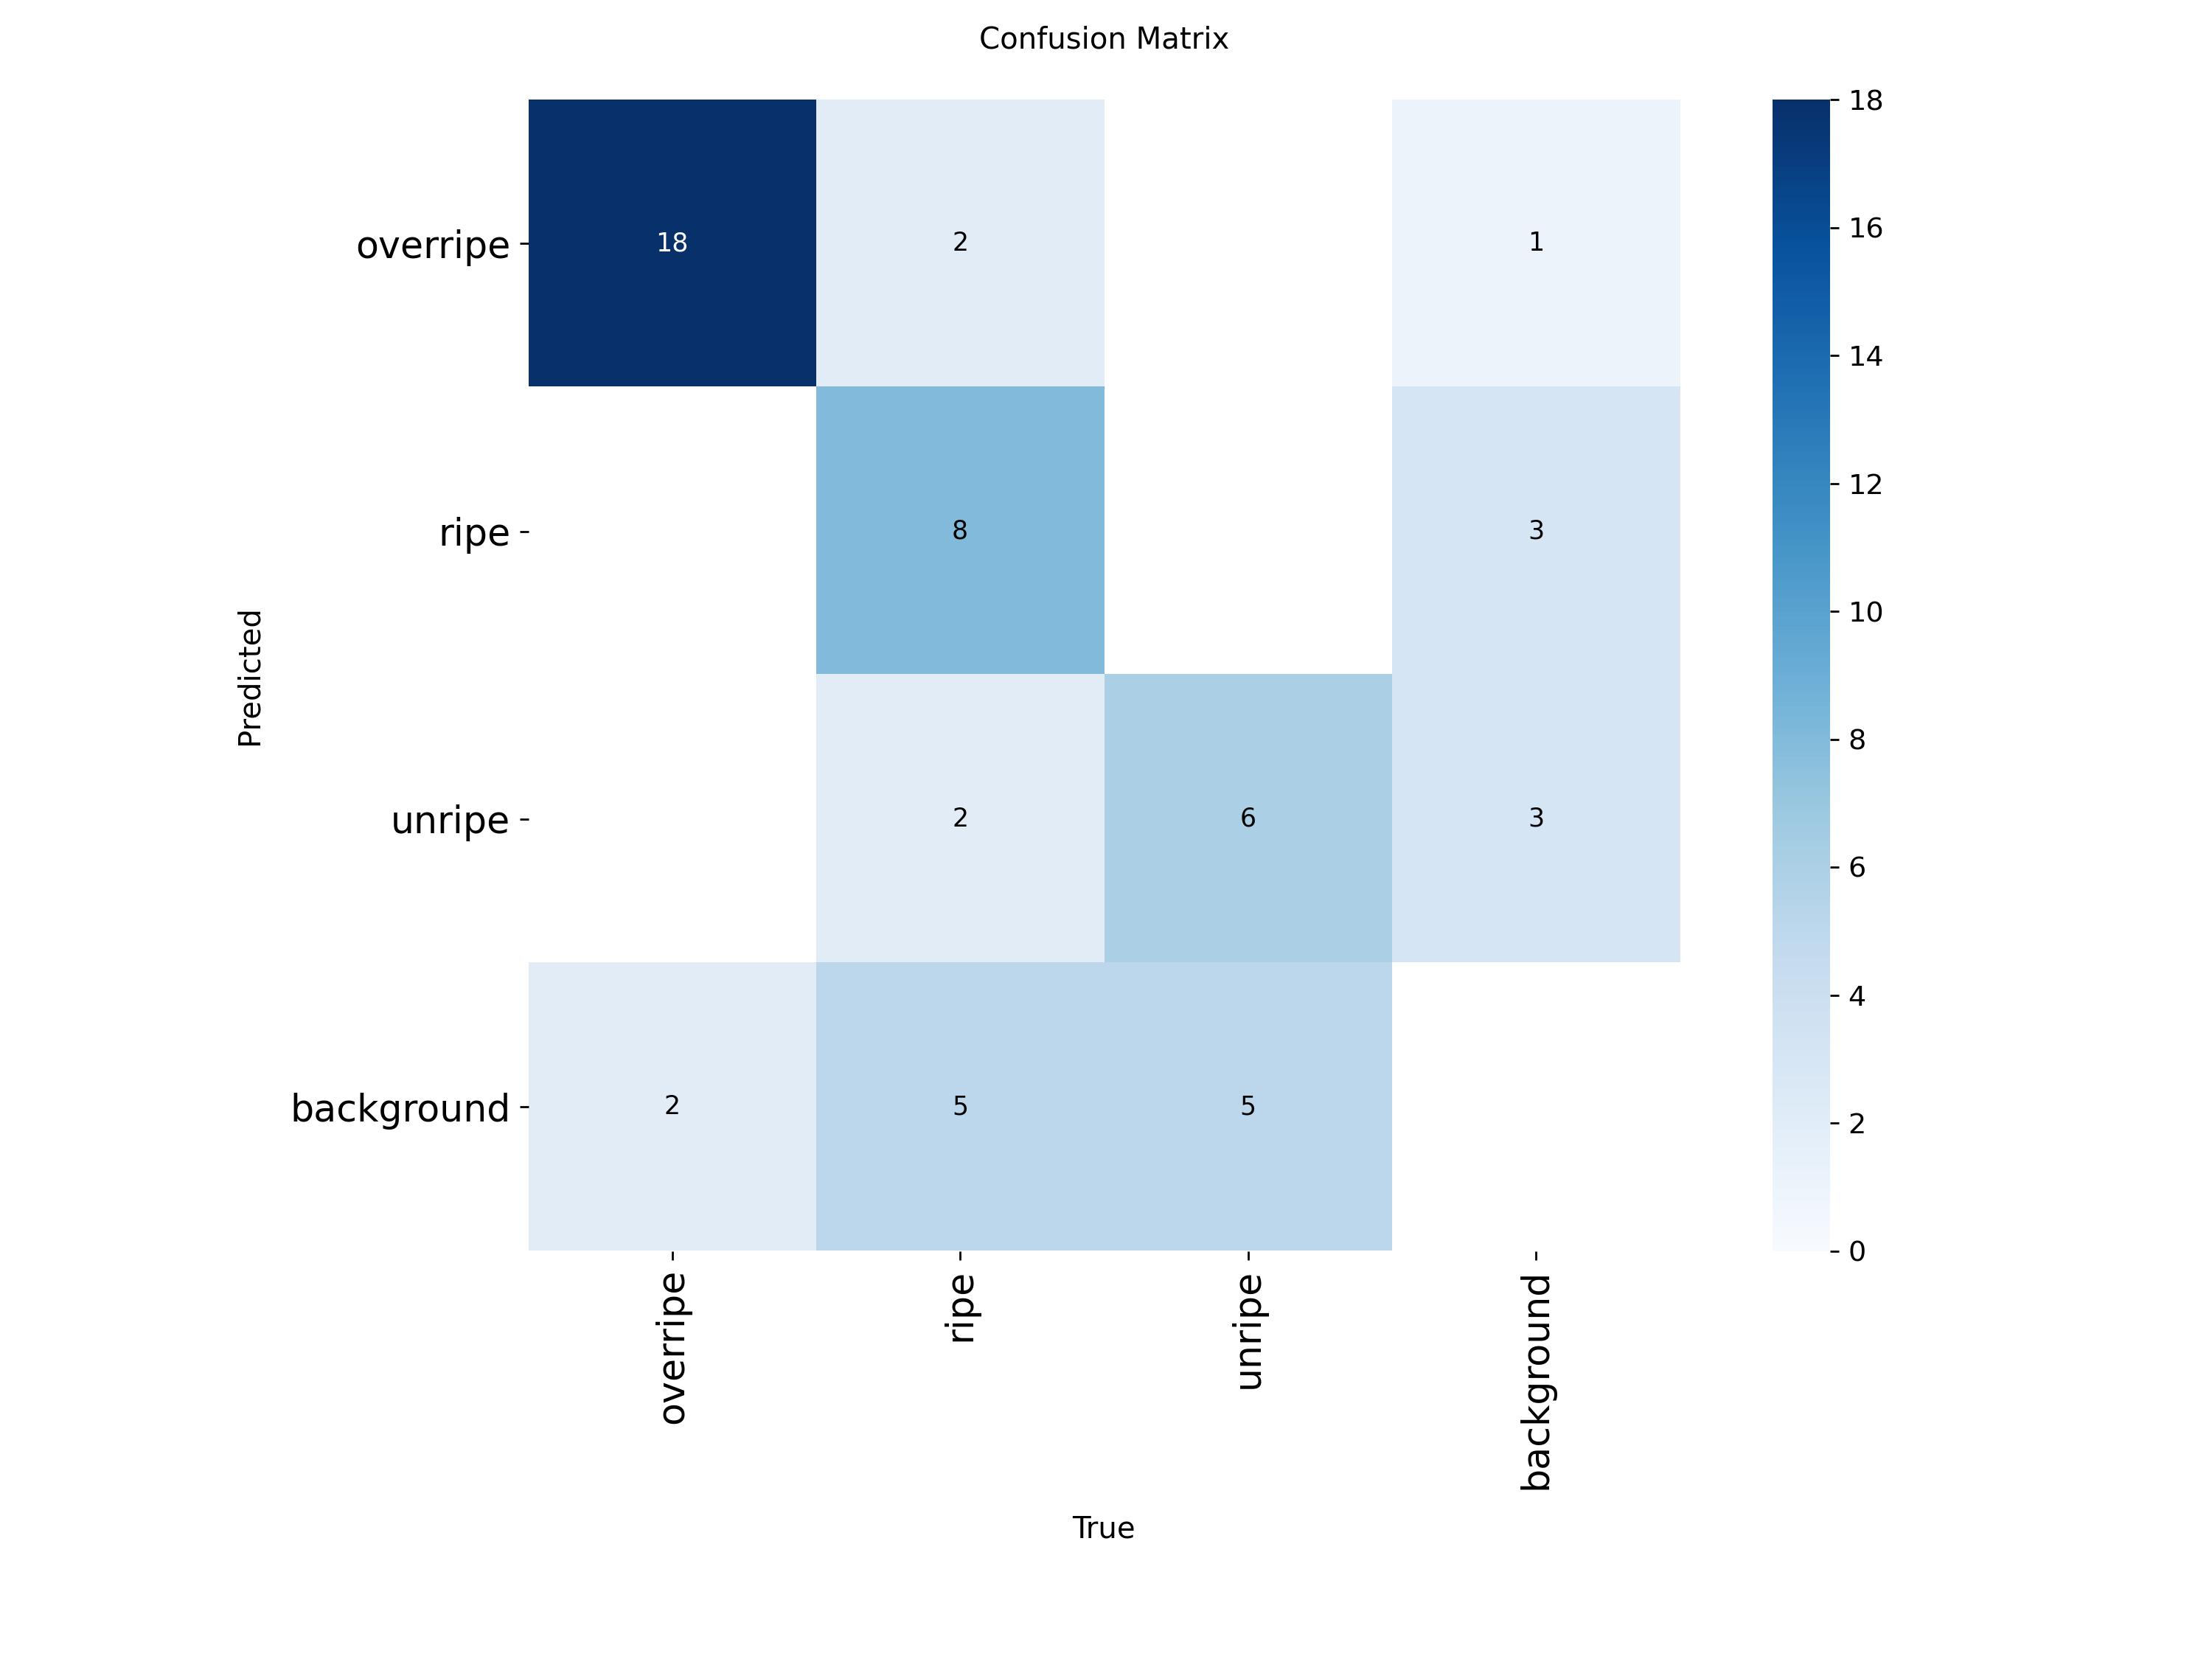

In [39]:
# ============================================================
# CELL 15 — DISPLAY TEST-SET CONFUSION MATRIX
# ============================================================

import os
from PIL import Image
from IPython.display import display

test_results_folder = r"C:\Users\Lenovo\OneDrive\Documents\Robotics_projectt\Robotics_project\runs\detect\val-3"

confusion_matrix_path = os.path.join(
    test_results_folder,
    "confusion_matrix.png"
)

print("Confusion matrix path:")
print(confusion_matrix_path)

print()
print("File exists:", os.path.isfile(confusion_matrix_path))

if os.path.isfile(confusion_matrix_path):

    confusion_matrix_image = Image.open(
        confusion_matrix_path
    )

    print()
    print("Test-set confusion matrix:")
    display(confusion_matrix_image)

else:
    print("confusion_matrix.png was not found.")

In [40]:
# ============================================================
# CELL 16 — DISPLAY TEST IMAGES WITH PREDICTIONS
# ============================================================

import matplotlib.pyplot as plt

# Select a few test images
test_images_path = r"C:\Users\Lenovo\OneDrive\Documents\Robotics_projectt\Robotics_project\apple_ripeness_detection\test\images"

test_files = sorted([
    f for f in os.listdir(test_images_path)
    if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp"))
])

# Select first 6 images
selected_files = test_files[:6]

for file_name in selected_files:

    image_path = os.path.join(
        test_images_path,
        file_name
    )

    # Run prediction
    results = trained_model.predict(
        source=image_path,
        imgsz=640,
        conf=0.25,
        device="cpu",
        verbose=False
    )

    result_img = results[0]

    # Get YOLO annotated image
    annotated_image = result_img.plot()

    # Convert BGR to RGB for matplotlib
    annotated_image = annotated_image[:, :, ::-1]

    plt.figure(figsize=(8, 8))
    plt.imshow(annotated_image)
    plt.title(file_name)
    plt.axis("off")
    plt.show()

<Figure size 800x800 with 1 Axes>

<Figure size 800x800 with 1 Axes>

<Figure size 800x800 with 1 Axes>

<Figure size 800x800 with 1 Axes>

<Figure size 800x800 with 1 Axes>

<Figure size 800x800 with 1 Axes>

In [41]:
# ============================================================
# CELL 17 — COMPARE GROUND TRUTH AND PREDICTIONS
# ============================================================

# Paths
test_images_path = r"C:\Users\Lenovo\OneDrive\Documents\Robotics_projectt\Robotics_project\apple_ripeness_detection\test\images"

test_labels_path = r"C:\Users\Lenovo\OneDrive\Documents\Robotics_projectt\Robotics_project\apple_ripeness_detection\test\labels"

# Class names
class_names = {
    0: "overripe",
    1: "ripe",
    2: "unripe"
}

# Get test images
test_files = sorted([
    f for f in os.listdir(test_images_path)
    if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp"))
])

print("Ground truth vs prediction")
print("=" * 80)

# Check first 10 test images
for file_name in test_files[:10]:

    image_stem = os.path.splitext(file_name)[0]

    image_path = os.path.join(
        test_images_path,
        file_name
    )

    label_path = os.path.join(
        test_labels_path,
        image_stem + ".txt"
    )

    # --------------------------------------------------------
    # Read ground-truth labels
    # --------------------------------------------------------

    ground_truth_classes = []

    if os.path.isfile(label_path):

        with open(label_path, "r") as f:

            for line in f:

                parts = line.strip().split()

                if len(parts) >= 5:

                    class_id = int(parts[0])

                    if class_id in class_names:
                        ground_truth_classes.append(
                            class_names[class_id]
                        )

    # --------------------------------------------------------
    # Run model prediction
    # --------------------------------------------------------

    predictions = trained_model.predict(
        source=image_path,
        imgsz=640,
        conf=0.25,
        device="cpu",
        verbose=False
    )

    result_check = predictions[0]

    predicted_classes = []

    if (
        result_check.boxes is not None
        and len(result_check.boxes) > 0
    ):

        for box in result_check.boxes:

            class_id = int(box.cls[0].item())

            if class_id in class_names:
                predicted_classes.append(
                    class_names[class_id]
                )

    # --------------------------------------------------------
    # Print comparison
    # --------------------------------------------------------

    print()
    print("Image:", file_name)
    print("Ground truth:", ground_truth_classes)
    print("Prediction   :", predicted_classes)

    if set(ground_truth_classes) == set(predicted_classes):
        print("Status       : MATCH")
    else:
        print("Status       : DIFFERENT")

Ground truth vs prediction

Image: Screen-Shot-2018-06-07-at-2-16-18-PM_png.rf.d51a11f032c53c5b4c0da7aea7441a5b.jpg
Ground truth: ['overripe']
Prediction   : ['overripe']
Status       : MATCH

Image: Screen-Shot-2018-06-07-at-2-18-57-PM_png.rf.702bed4ec50663e4b6d202a81f2aa58f.jpg
Ground truth: ['overripe']
Prediction   : ['ripe']
Status       : DIFFERENT

Image: Screen-Shot-2018-06-07-at-2-20-46-PM_png.rf.2b45cb751e7cc876bd7b0a849401c0ae.jpg
Ground truth: ['overripe']
Prediction   : []
Status       : DIFFERENT

Image: Screen-Shot-2018-06-07-at-2-31-43-PM_png.rf.17110f544778a282c885e7b0dc84f78d.jpg
Ground truth: ['overripe']
Prediction   : ['overripe']
Status       : MATCH

Image: Screen-Shot-2018-06-07-at-2-35-21-PM_png.rf.2a534c74b0df83d2a4b92e083b0736ae.jpg
Ground truth: ['overripe']
Prediction   : ['overripe']
Status       : MATCH

Image: Screen-Shot-2018-06-07-at-2-37-20-PM_png.rf.b9952f0bf9421f62396e984bba42c8b9.jpg
Ground truth: ['overripe']
Prediction   : ['overripe']
Status    

In [42]:
# ============================================================
# CELL 18 — COMPARE ALL THREE RIPENESS CLASSES
# ============================================================

# Paths
test_images_path = r"C:\Users\Lenovo\OneDrive\Documents\Robotics_projectt\Robotics_project\apple_ripeness_detection\test\images"

test_labels_path = r"C:\Users\Lenovo\OneDrive\Documents\Robotics_projectt\Robotics_project\apple_ripeness_detection\test\labels"

# Class names
class_names = {
    0: "overripe",
    1: "ripe",
    2: "unripe"
}

# Store one example for each class
selected_examples = {}

# ------------------------------------------------------------
# Find one test image for each class
# ------------------------------------------------------------

test_files = sorted([
    f for f in os.listdir(test_images_path)
    if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp"))
])

for file_name in test_files:

    image_stem = os.path.splitext(file_name)[0]

    label_path = os.path.join(
        test_labels_path,
        image_stem + ".txt"
    )

    if not os.path.isfile(label_path):
        continue

    with open(label_path, "r") as f:

        for line in f:

            parts = line.strip().split()

            if len(parts) >= 5:

                class_id = int(parts[0])

                if class_id in class_names:

                    class_name = class_names[class_id]

                    if class_name not in selected_examples:
                        selected_examples[class_name] = file_name

# ------------------------------------------------------------
# Print selected examples
# ------------------------------------------------------------

print("Selected test examples:")
print()

for class_name in class_names.values():

    if class_name in selected_examples:
        print(
            f"{class_name:<10} -> "
            f"{selected_examples[class_name]}"
        )
    else:
        print(
            f"{class_name:<10} -> No example found"
        )

# ------------------------------------------------------------
# Run prediction on selected examples
# ------------------------------------------------------------

print()
print("=" * 80)
print("GROUND TRUTH VS MODEL PREDICTION")
print("=" * 80)

for actual_class, file_name in selected_examples.items():

    image_path = os.path.join(
        test_images_path,
        file_name
    )

    results = trained_model.predict(
        source=image_path,
        imgsz=640,
        conf=0.25,
        device="cpu",
        verbose=False
    )

    result_check = results[0]

    predicted_classes = []
    confidences = []

    if (
        result_check.boxes is not None
        and len(result_check.boxes) > 0
    ):

        for box in result_check.boxes:

            class_id = int(box.cls[0].item())
            confidence = float(box.conf[0].item())

            if class_id in class_names:

                predicted_classes.append(
                    class_names[class_id]
                )

                confidences.append(
                    confidence
                )

    print()
    print("Actual class :", actual_class)
    print("Image        :", file_name)
    print("Prediction   :", predicted_classes)
    print(
        "Confidence   :",
        [f"{c:.3f}" for c in confidences]
        if confidences else "No detection"
    )

Selected test examples:

overripe   -> Screen-Shot-2018-06-07-at-2-16-18-PM_png.rf.d51a11f032c53c5b4c0da7aea7441a5b.jpg
ripe       -> Screen-Shot-2018-06-08-at-5-10-29-PM_png.rf.fded39a548978e36878307eb6e7cbef6.jpg
unripe     -> rotated_by_15_Screen-Shot-2018-06-08-at-5-26-41-PM_png.rf.54c14e5a10241da6c974d51eb56d94dd.jpg

GROUND TRUTH VS MODEL PREDICTION

Actual class : overripe
Image        : Screen-Shot-2018-06-07-at-2-16-18-PM_png.rf.d51a11f032c53c5b4c0da7aea7441a5b.jpg
Prediction   : ['overripe']
Confidence   : ['0.259']

Actual class : ripe
Image        : Screen-Shot-2018-06-08-at-5-10-29-PM_png.rf.fded39a548978e36878307eb6e7cbef6.jpg
Prediction   : ['ripe']
Confidence   : ['0.908']

Actual class : unripe
Image        : rotated_by_15_Screen-Shot-2018-06-08-at-5-26-41-PM_png.rf.54c14e5a10241da6c974d51eb56d94dd.jpg
Prediction   : []
Confidence   : No detection


In [43]:
# ============================================================
# CELL 19 — INSPECT UNRIPE IMAGE AT LOW CONFIDENCE
# ============================================================

unripe_image_path = os.path.join(
    test_images_path,
    selected_examples["unripe"]
)

# Run with a very low confidence threshold
low_conf_results = trained_model.predict(
    source=unripe_image_path,
    imgsz=640,
    conf=0.01,
    device="cpu",
    verbose=False
)

low_conf_result = low_conf_results[0]

print("Image:")
print(unripe_image_path)

print()
print("Predictions at confidence threshold = 0.01")
print("=" * 60)

if (
    low_conf_result.boxes is not None
    and len(low_conf_result.boxes) > 0
):

    for i, box in enumerate(low_conf_result.boxes):

        class_id = int(box.cls[0].item())
        class_name = trained_model.names[class_id]
        confidence = float(box.conf[0].item())

        x1, y1, x2, y2 = box.xyxy[0].tolist()

        print(f"Detection {i + 1}")
        print("Class      :", class_name)
        print(f"Confidence : {confidence:.4f}")
        print(
            f"Box        : "
            f"({x1:.1f}, {y1:.1f}) -> "
            f"({x2:.1f}, {y2:.1f})"
        )
        print()

else:
    print("No detections even at confidence 0.01.")

Image:
C:\Users\Lenovo\OneDrive\Documents\Robotics_projectt\Robotics_project\apple_ripeness_detection\test\images\rotated_by_15_Screen-Shot-2018-06-08-at-5-26-41-PM_png.rf.54c14e5a10241da6c974d51eb56d94dd.jpg

Predictions at confidence threshold = 0.01
Detection 1
Class      : unripe
Confidence : 0.2128
Box        : (65.7, 52.9) -> (478.8, 453.2)

Detection 2
Class      : unripe
Confidence : 0.1063
Box        : (66.0, 57.1) -> (479.0, 454.2)



In [44]:
# ============================================================
# CELL 20 — TEST DIFFERENT CONFIDENCE THRESHOLDS
# ============================================================

confidence_thresholds = [
    0.01,
    0.05,
    0.10,
    0.15,
    0.20,
    0.25,
    0.30,
    0.40,
    0.50
]

print("Unripe image:")
print(unripe_image_path)
print()

for threshold in confidence_thresholds:

    results_threshold = trained_model.predict(
        source=unripe_image_path,
        imgsz=640,
        conf=threshold,
        device="cpu",
        verbose=False
    )

    result_threshold = results_threshold[0]

    detections = []

    if (
        result_threshold.boxes is not None
        and len(result_threshold.boxes) > 0
    ):

        for box in result_threshold.boxes:

            class_id = int(box.cls[0].item())
            class_name = trained_model.names[class_id]
            confidence = float(box.conf[0].item())

            detections.append(
                f"{class_name} ({confidence:.3f})"
            )

    if detections:
        print(
            f"conf={threshold:.2f} -> "
            + ", ".join(detections)
        )
    else:
        print(
            f"conf={threshold:.2f} -> No detection"
        )

Unripe image:
C:\Users\Lenovo\OneDrive\Documents\Robotics_projectt\Robotics_project\apple_ripeness_detection\test\images\rotated_by_15_Screen-Shot-2018-06-08-at-5-26-41-PM_png.rf.54c14e5a10241da6c974d51eb56d94dd.jpg

conf=0.01 -> unripe (0.213), unripe (0.106)
conf=0.05 -> unripe (0.213), unripe (0.106)
conf=0.10 -> unripe (0.213), unripe (0.106)
conf=0.15 -> unripe (0.213)
conf=0.20 -> unripe (0.213)
conf=0.25 -> No detection
conf=0.30 -> No detection
conf=0.40 -> No detection
conf=0.50 -> No detection


In [45]:
# ============================================================
# CELL 21 — COMPLETE TEST-SET PREDICTION ANALYSIS
# ============================================================

from collections import Counter

# Paths
test_images_path = r"C:\Users\Lenovo\OneDrive\Documents\Robotics_projectt\Robotics_project\apple_ripeness_detection\test\images"
test_labels_path = r"C:\Users\Lenovo\OneDrive\Documents\Robotics_projectt\Robotics_project\apple_ripeness_detection\test\labels"

class_names = {
    0: "overripe",
    1: "ripe",
    2: "unripe"
}

# Counters
total_images = 0
correct = 0
wrong_class = 0
missed = 0
multiple_predictions = 0

class_results = {
    "overripe": Counter(),
    "ripe": Counter(),
    "unripe": Counter()
}

# Get all test images
test_files = sorted([
    f for f in os.listdir(test_images_path)
    if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp"))
])

print("Analyzing complete test set...")
print("Total test images:", len(test_files))
print()

for file_name in test_files:

    image_stem = os.path.splitext(file_name)[0]

    image_path = os.path.join(
        test_images_path,
        file_name
    )

    label_path = os.path.join(
        test_labels_path,
        image_stem + ".txt"
    )

    # --------------------------------------------------------
    # Get ground-truth class
    # --------------------------------------------------------

    ground_truth = []

    if os.path.isfile(label_path):

        with open(label_path, "r") as f:

            for line in f:

                parts = line.strip().split()

                if len(parts) >= 5:

                    class_id = int(parts[0])

                    if class_id in class_names:
                        ground_truth.append(
                            class_names[class_id]
                        )

    # Skip images without a valid ground truth class
    if len(ground_truth) == 0:
        continue

    actual_class = ground_truth[0]

    # --------------------------------------------------------
    # Run prediction
    # --------------------------------------------------------

    prediction = trained_model.predict(
        source=image_path,
        imgsz=640,
        conf=0.25,
        device="cpu",
        verbose=False
    )[0]

    predicted = []

    if (
        prediction.boxes is not None
        and len(prediction.boxes) > 0
    ):

        for box in prediction.boxes:

            class_id = int(box.cls[0].item())

            if class_id in class_names:
                predicted.append(
                    class_names[class_id]
                )

    total_images += 1

    # --------------------------------------------------------
    # Categorize result
    # --------------------------------------------------------

    if len(predicted) == 0:

        missed += 1
        class_results[actual_class]["missed"] += 1

    elif actual_class in predicted:

        correct += 1
        class_results[actual_class]["correct"] += 1

        if len(predicted) > 1:
            multiple_predictions += 1
            class_results[actual_class]["multiple"] += 1

    else:

        wrong_class += 1
        class_results[actual_class]["wrong_class"] += 1

# ------------------------------------------------------------
# Print summary
# ------------------------------------------------------------

print("=" * 70)
print("TEST-SET ANALYSIS")
print("=" * 70)

print()
print("Total images analyzed :", total_images)
print("Correct detections    :", correct)
print("Wrong class           :", wrong_class)
print("Missed detections     :", missed)
print("Multiple predictions  :", multiple_predictions)

if total_images > 0:

    print()
    print(f"Correct rate: {correct / total_images * 100:.2f}%")

    print()
    print("=" * 70)
    print("PER-CLASS RESULTS")
    print("=" * 70)

    for class_name in class_names.values():

        results = class_results[class_name]

        print()
        print(class_name.upper())
        print("  Correct        :", results["correct"])
        print("  Wrong class    :", results["wrong_class"])
        print("  Missed         :", results["missed"])
        print("  Multiple       :", results["multiple"])

Analyzing complete test set...
Total test images: 46

TEST-SET ANALYSIS

Total images analyzed : 46
Correct detections    : 36
Wrong class           : 5
Missed detections     : 5
Multiple predictions  : 5

Correct rate: 78.26%

PER-CLASS RESULTS

OVERRIPE
  Correct        : 18
  Wrong class    : 1
  Missed         : 1
  Multiple       : 1

RIPE
  Correct        : 12
  Wrong class    : 4
  Missed         : 0
  Multiple       : 4

UNRIPE
  Correct        : 6
  Wrong class    : 0
  Missed         : 4
  Multiple       : 0


In [46]:
# ============================================================
# CELL 22 — COUNT DATASET INSTANCES BY CLASS
# ============================================================

from collections import Counter

dataset_root = r"C:\Users\Lenovo\OneDrive\Documents\Robotics_projectt\Robotics_project\apple_ripeness_detection"

class_names = {
    0: "overripe",
    1: "ripe",
    2: "unripe"
}

splits = ["train", "valid", "test"]

print("=" * 70)
print("DATASET CLASS DISTRIBUTION")
print("=" * 70)

for split in splits:

    labels_path = os.path.join(
        dataset_root,
        split,
        "labels"
    )

    counts = Counter()

    label_files = [
        f for f in os.listdir(labels_path)
        if f.lower().endswith(".txt")
    ]

    for label_file in label_files:

        label_path = os.path.join(
            labels_path,
            label_file
        )

        with open(label_path, "r") as f:

            for line in f:

                parts = line.strip().split()

                if len(parts) >= 5:

                    class_id = int(parts[0])

                    if class_id in class_names:
                        counts[class_names[class_id]] += 1

    print()
    print(split.upper())
    print("-" * 40)

    total = sum(counts.values())

    for class_name in class_names.values():

        count = counts[class_name]

        percentage = (
            count / total * 100
            if total > 0
            else 0
        )

        print(
            f"{class_name:<10}: "
            f"{count:4d} instances "
            f"({percentage:.1f}%)"
        )

    print(f"{'TOTAL':<10}: {total:4d} instances")

DATASET CLASS DISTRIBUTION

TRAIN
----------------------------------------
overripe  :  909 instances (70.3%)
ripe      :  144 instances (11.1%)
unripe    :  240 instances (18.6%)
TOTAL     : 1293 instances

VALID
----------------------------------------
overripe  :   32 instances (23.0%)
ripe      :   88 instances (63.3%)
unripe    :   19 instances (13.7%)
TOTAL     :  139 instances

TEST
----------------------------------------
overripe  :   20 instances (41.7%)
ripe      :   17 instances (35.4%)
unripe    :   11 instances (22.9%)
TOTAL     :   48 instances


In [47]:
# ============================================================
# CELL 23 — COUNT IMAGES CONTAINING EACH CLASS
# ============================================================

from collections import Counter

dataset_root = r"C:\Users\Lenovo\OneDrive\Documents\Robotics_projectt\Robotics_project\apple_ripeness_detection"

class_names = {
    0: "overripe",
    1: "ripe",
    2: "unripe"
}

splits = ["train", "valid", "test"]

print("=" * 70)
print("IMAGE-LEVEL CLASS DISTRIBUTION")
print("=" * 70)

for split in splits:

    labels_path = os.path.join(
        dataset_root,
        split,
        "labels"
    )

    image_counts = Counter()

    label_files = [
        f for f in os.listdir(labels_path)
        if f.lower().endswith(".txt")
    ]

    for label_file in label_files:

        label_path = os.path.join(
            labels_path,
            label_file
        )

        classes_in_image = set()

        with open(label_path, "r") as f:

            for line in f:

                parts = line.strip().split()

                if len(parts) >= 5:

                    class_id = int(parts[0])

                    if class_id in class_names:
                        classes_in_image.add(class_names[class_id])

        # Count the image once for each class it contains
        for class_name in classes_in_image:
            image_counts[class_name] += 1

    print()
    print(split.upper())
    print("-" * 40)

    for class_name in class_names.values():

        print(
            f"{class_name:<10}: "
            f"{image_counts[class_name]} images"
        )

IMAGE-LEVEL CLASS DISTRIBUTION

TRAIN
----------------------------------------
overripe  : 885 images
ripe      : 141 images
unripe    : 225 images

VALID
----------------------------------------
overripe  : 31 images
ripe      : 84 images
unripe    : 19 images

TEST
----------------------------------------
overripe  : 20 images
ripe      : 16 images
unripe    : 10 images


Original dataset training images: 1278

Sample image:
C:\Users\Lenovo\OneDrive\Documents\Robotics_projectt\Robotics_project\apple-ripeness-detection.v1i.yolov8\train\images\rotated_by_15_Screen-Shot-2018-06-07-at-2-57-49-PM_png.rf.4ca26e0cbe4ec9da671c5cacb6b80754.jpg

Image mode: RGB
Image shape: (512, 512, 3)

RESULT: Original image is also visually grayscale.

Displaying original image:


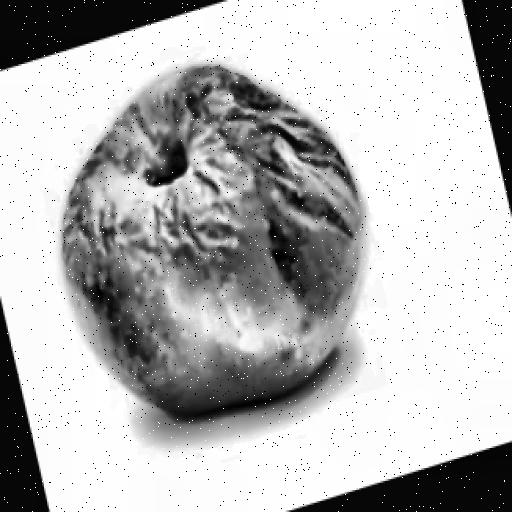

In [48]:
# ============================================================
# CELL 24 — CHECK ORIGINAL DATASET FOR COLOR INFORMATION
# ============================================================

original_train_path = r"C:\Users\Lenovo\OneDrive\Documents\Robotics_projectt\Robotics_project\apple-ripeness-detection.v1i.yolov8\train\images"

original_files = [
    f for f in os.listdir(original_train_path)
    if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp"))
]

print("Original dataset training images:", len(original_files))

if len(original_files) > 0:

    sample_original_path = os.path.join(
        original_train_path,
        original_files[0]
    )

    original_image = Image.open(
        sample_original_path
    )

    original_array = np.array(original_image)

    print()
    print("Sample image:")
    print(sample_original_path)

    print()
    print("Image mode:", original_image.mode)
    print("Image shape:", original_array.shape)

    if (
        len(original_array.shape) == 3
        and original_array.shape[2] >= 3
    ):

        r = original_array[:, :, 0]
        g = original_array[:, :, 1]
        b = original_array[:, :, 2]

        print()

        if (
            np.array_equal(r, g)
            and np.array_equal(g, b)
        ):
            print("RESULT: Original image is also visually grayscale.")
        else:
            print("RESULT: Original image contains COLOR information.")

    print()
    print("Displaying original image:")
    display(original_image)